# Plot joli RMSE

In [1]:
import json
import glob
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [2]:

database_path = "/Odyssey/private/j25lee/glonet/gradient_descent_optimic/outputs/forecast_exp/perfectIC_ose"

# Find all directories matching the pattern "idx*_but0_osse_obs_*"
# pattern = os.path.join(database_path, "idx*_but0_perfect_obs_*")
pattern = os.path.join(database_path, "*")

osse_obs_dirs = sorted(glob.glob(pattern))

print(f"Found {len(osse_obs_dirs)} directories with '{pattern}' pattern:")
for d in osse_obs_dirs:
    print(f"  {os.path.basename(d)}")

Found 30 directories with '/Odyssey/private/j25lee/glonet/gradient_descent_optimic/outputs/forecast_exp/perfectIC_ose/*' pattern:
  perfectIC_ose_idx0_but0_20260524_174528
  perfectIC_ose_idx10_but0_20260525_073245
  perfectIC_ose_idx11_but0_20260525_073707
  perfectIC_ose_idx12_but0_20260525_140115
  perfectIC_ose_idx13_but0_20260525_140340
  perfectIC_ose_idx14_but0_20260525_142316
  perfectIC_ose_idx15_but0_20260525_143025
  perfectIC_ose_idx16_but0_20260525_204815
  perfectIC_ose_idx17_but0_20260525_204815
  perfectIC_ose_idx18_but0_20260525_211352
  perfectIC_ose_idx19_but0_20260525_212410
  perfectIC_ose_idx1_but0_20260524_174528
  perfectIC_ose_idx20_but0_20260526_033047
  perfectIC_ose_idx21_but0_20260526_033342
  perfectIC_ose_idx22_but0_20260526_040502
  perfectIC_ose_idx23_but0_20260526_041735
  perfectIC_ose_idx24_but0_20260526_101407
  perfectIC_ose_idx25_but0_20260526_101735
  perfectIC_ose_idx26_but0_20260526_105628
  perfectIC_ose_idx27_but0_20260526_111207
  perfectIC_

In [3]:

# Load RMSE data from all directories
data_dict = {}

for directory in osse_obs_dirs:
    json_path = os.path.join(directory, "rmse_step_comparison.json")
    if os.path.exists(json_path):
        with open(json_path, 'r') as f:
            data = json.load(f)
        
        # Extract the idx number from directory name
        dir_name = os.path.basename(directory)
        idx_num = int(dir_name.split('_')[2].replace('idx', ''))
        
        data_dict[idx_num] = {
            'directory': directory,
            'data': data
        }
        print(f"Loaded idx{idx_num} from {os.path.basename(directory)}")

print(f"\nTotal datasets loaded: {len(data_dict)}")

# Display structure of first dataset
if data_dict:
    first_idx = min(data_dict.keys())
    first_data = data_dict[first_idx]['data']
    print(f"\nData structure for idx{first_idx}:")
    print(f"  Keys: {list(first_data.keys())}")
    print(f"  Channels: {first_data['channel_names']}")
    print(f"  Number of steps: {len(first_data['steps'])}")
    print(f"  Steps: {first_data['steps'][:5]}...")  # Show first 5 steps


Loaded idx0 from perfectIC_ose_idx0_but0_20260524_174528
Loaded idx10 from perfectIC_ose_idx10_but0_20260525_073245
Loaded idx11 from perfectIC_ose_idx11_but0_20260525_073707
Loaded idx12 from perfectIC_ose_idx12_but0_20260525_140115
Loaded idx13 from perfectIC_ose_idx13_but0_20260525_140340
Loaded idx14 from perfectIC_ose_idx14_but0_20260525_142316
Loaded idx15 from perfectIC_ose_idx15_but0_20260525_143025
Loaded idx16 from perfectIC_ose_idx16_but0_20260525_204815
Loaded idx17 from perfectIC_ose_idx17_but0_20260525_204815
Loaded idx18 from perfectIC_ose_idx18_but0_20260525_211352
Loaded idx19 from perfectIC_ose_idx19_but0_20260525_212410
Loaded idx1 from perfectIC_ose_idx1_but0_20260524_174528
Loaded idx20 from perfectIC_ose_idx20_but0_20260526_033047
Loaded idx21 from perfectIC_ose_idx21_but0_20260526_033342
Loaded idx22 from perfectIC_ose_idx22_but0_20260526_040502
Loaded idx23 from perfectIC_ose_idx23_but0_20260526_041735
Loaded idx24 from perfectIC_ose_idx24_but0_20260526_101407
L

In [4]:
# Process data: compute global RMSE (mean across channels) for each step
processed_data = {}

for idx, data_info in data_dict.items():
    data = data_info['data']
    steps = np.array(data['steps'])
    
    # Convert to numpy arrays
    optimized_rmse = np.array(data['optimized_rmse_by_step'])
    reference_rmse = np.array(data['reference_rmse_by_step'])
    
    # Compute global RMSE (mean across all channels) for each step
    optimized_global = np.mean(optimized_rmse, axis=1)
    reference_global = np.mean(reference_rmse, axis=1)
    
    processed_data[idx] = {
        'steps': steps,
        'optimized_global': optimized_global,
        'reference_global': reference_global,
        'optimized_rmse': optimized_rmse,
        'reference_rmse': reference_rmse,
        'channels': data['channel_names']
    }

print(f"Processed {len(processed_data)} datasets")
print(f"Indices: {sorted(processed_data.keys())}")

Processed 30 datasets
Indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


ValueError: x and y must have same first dimension, but have shapes (30,) and (29,)

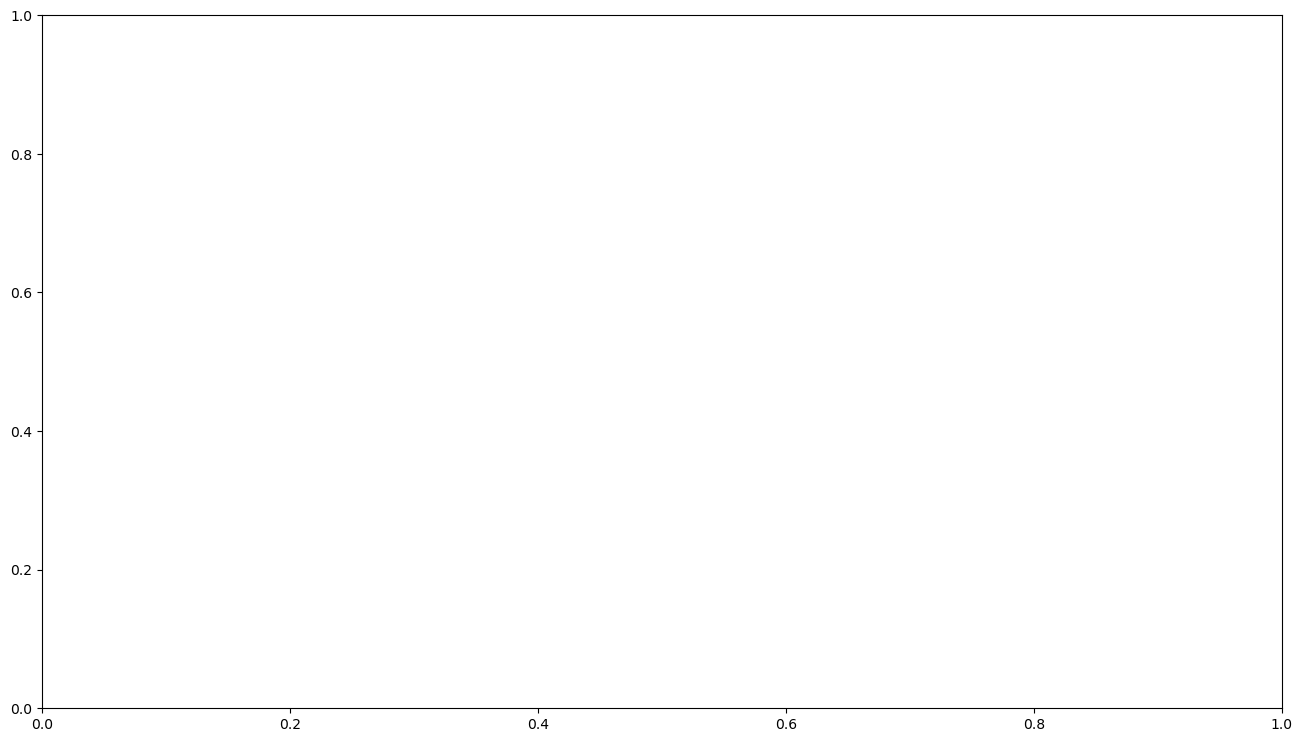

In [6]:
# Create ensemble-style superposed plots (individual members + mean)
 # Plot all individual runs with thin lines and bold mean
fig, ax = plt.subplots(1, 1, figsize=(16, 9))

# Determine common length across runs to avoid length mismatches
min_len = min(len(data['steps']) for data in processed_data.values())

# Collect all reference and optimized data (trimmed to common length)
all_ref_data = []
all_opt_data = []
steps = None

for idx in sorted(processed_data.keys()):
    data = processed_data[idx]
    data_steps = data['steps'][:min_len]
    all_ref_data.append(data['reference_global'][:min_len])
    all_opt_data.append(data['optimized_global'][:min_len])
    if steps is None:
        steps = data_steps

# Convert to arrays for easier manipulation
all_ref_data = np.array(all_ref_data)
all_opt_data = np.array(all_opt_data)

# Compute means
ref_mean = np.mean(all_ref_data, axis=0)
opt_mean = np.mean(all_opt_data, axis=0)

# Plot individual runs as thin lines (ensemble members)
 # Reference (blue)
for i, idx in enumerate(sorted(processed_data.keys())):
    data = processed_data[idx]
    data_steps = data['steps'][:min_len]
    ax.plot(data_steps, data['reference_global'][:min_len], color='blue', alpha=0.12, linewidth=0.6, zorder=1)

# Optimized (red)
for i, idx in enumerate(sorted(processed_data.keys())):
    data = processed_data[idx]
    data_steps = data['steps'][:min_len]
    ax.plot(data_steps, data['optimized_global'][:min_len], color='red', alpha=0.12, linewidth=0.6, zorder=1)

# Plot bold mean lines on top with markers
ax.plot(steps, ref_mean, color='blue', linewidth=4.5, label='Controls (Mean)', marker='o', 
        markersize=8, markeredgewidth=0.5, markeredgecolor='darkblue', zorder=10)
ax.plot(steps, opt_mean, color='red', linewidth=4.5, label='Optimized (Mean)', marker='s', 
        markersize=8, markeredgewidth=0.5, markeredgecolor='darkred', zorder=10)

ax.set_xlabel('Forecast Time Step', fontsize=14, fontweight='bold')
ax.set_ylabel('Global RMSE', fontsize=14, fontweight='bold')
ax.set_title('RMSE Development: All 30 Runs with Mean', fontsize=15, fontweight='bold')
ax.legend(loc='best', fontsize=12, framealpha=0.98)
ax.grid(True, alpha=0.5, linestyle='--')
ax.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()
plt.savefig(os.path.join(database_path, 'superposed_rmse_ensemble.png'), dpi=150, bbox_inches='tight')
print("Saved: superposed_rmse_ensemble.png")
plt.show()

Saved: superposed_rmse_ssh.png


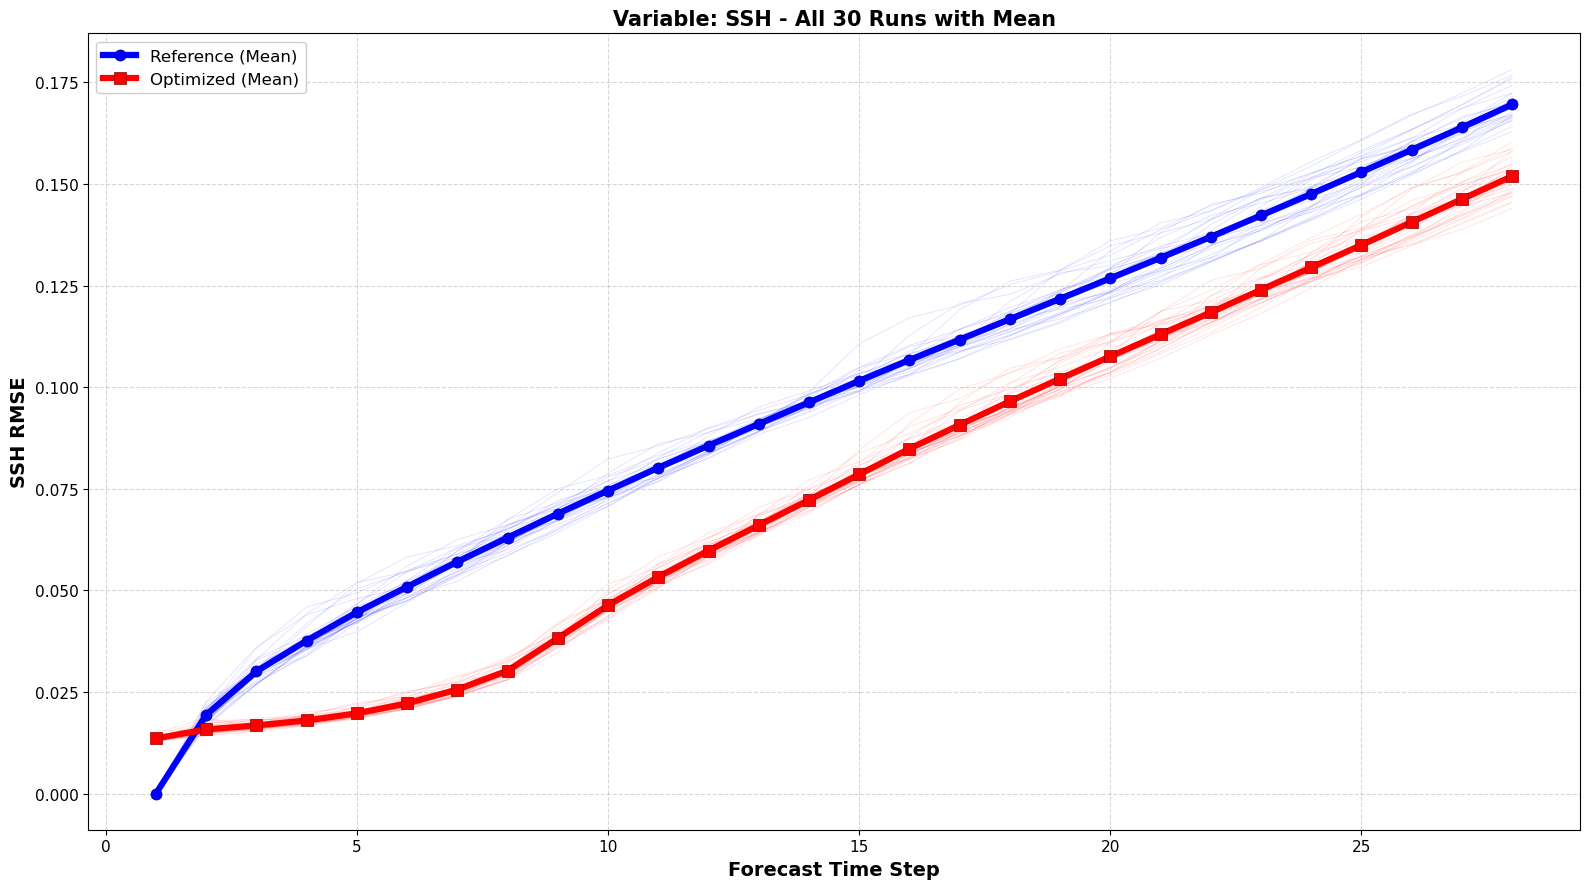

Saved: superposed_rmse_thetao.png


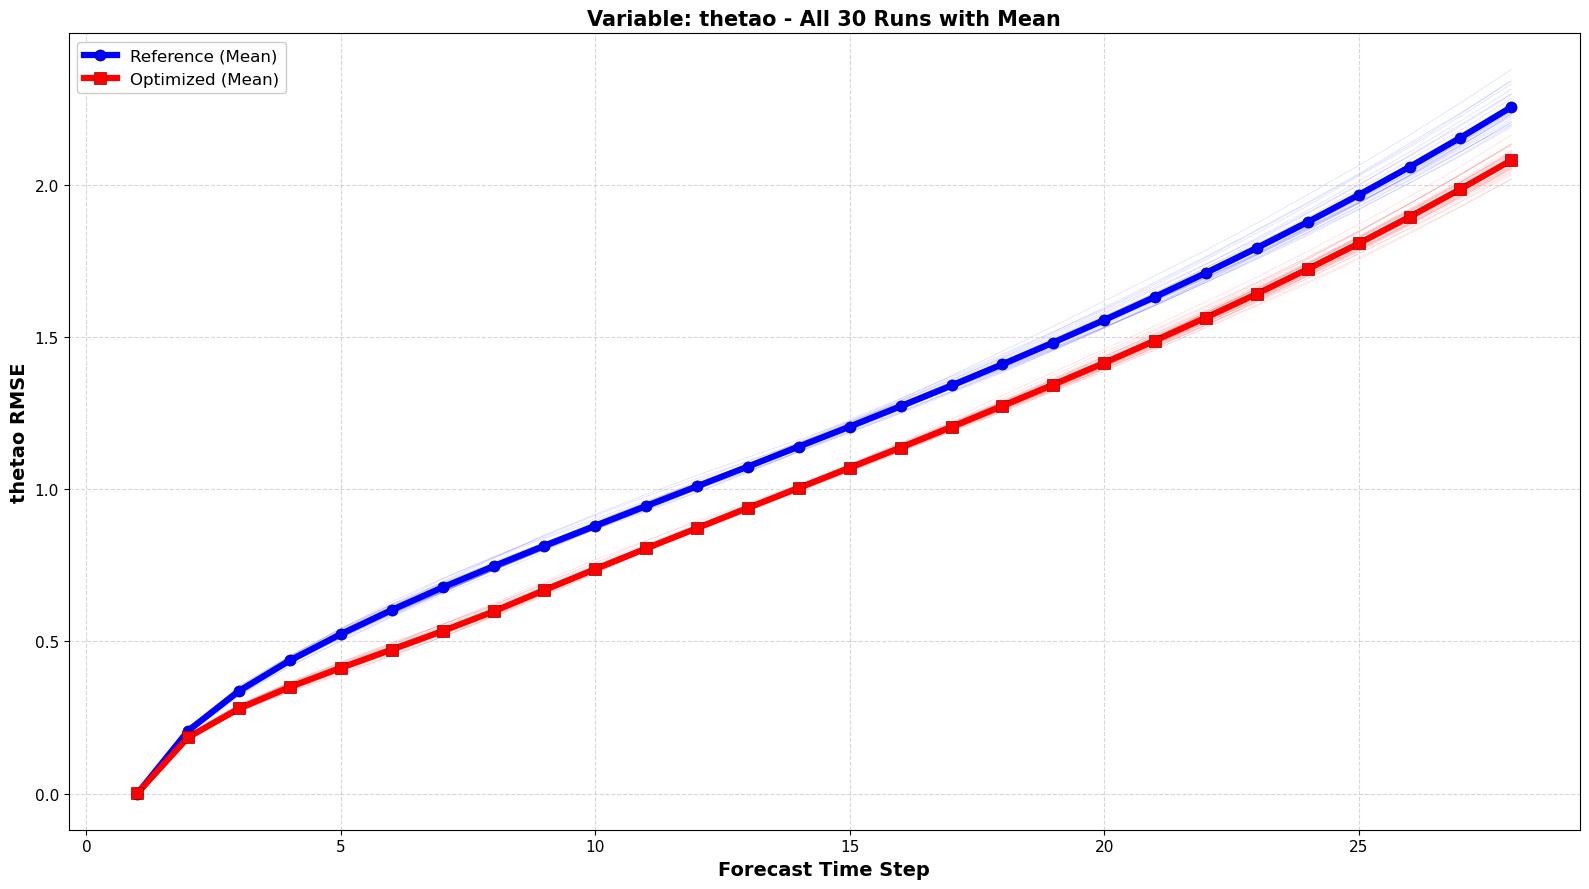

Saved: superposed_rmse_so.png


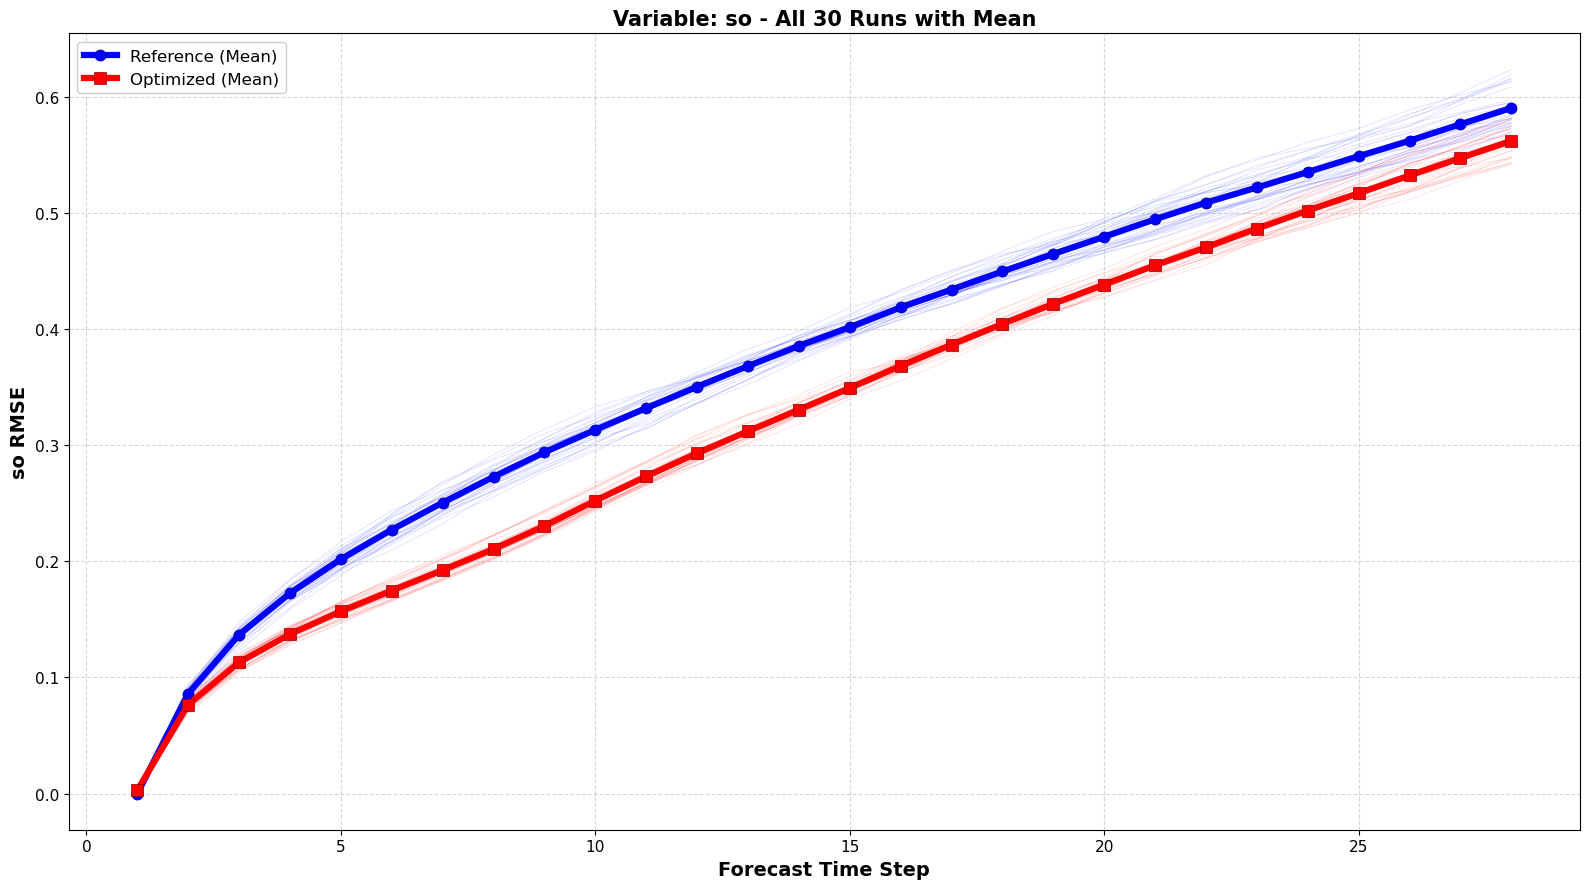

Saved: superposed_rmse_uo.png


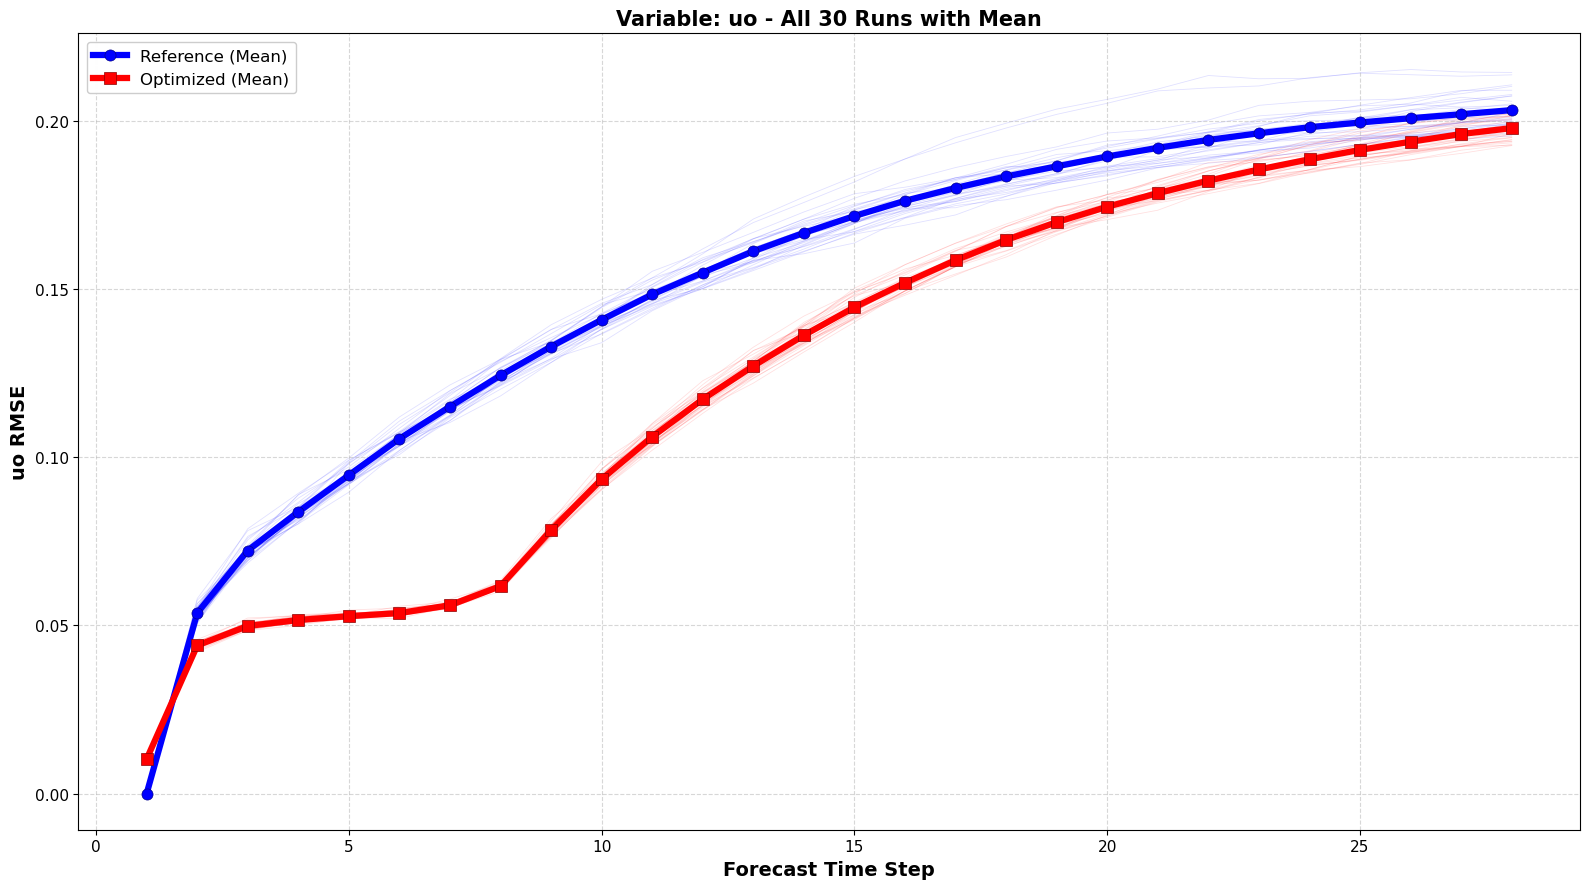

Saved: superposed_rmse_vo.png


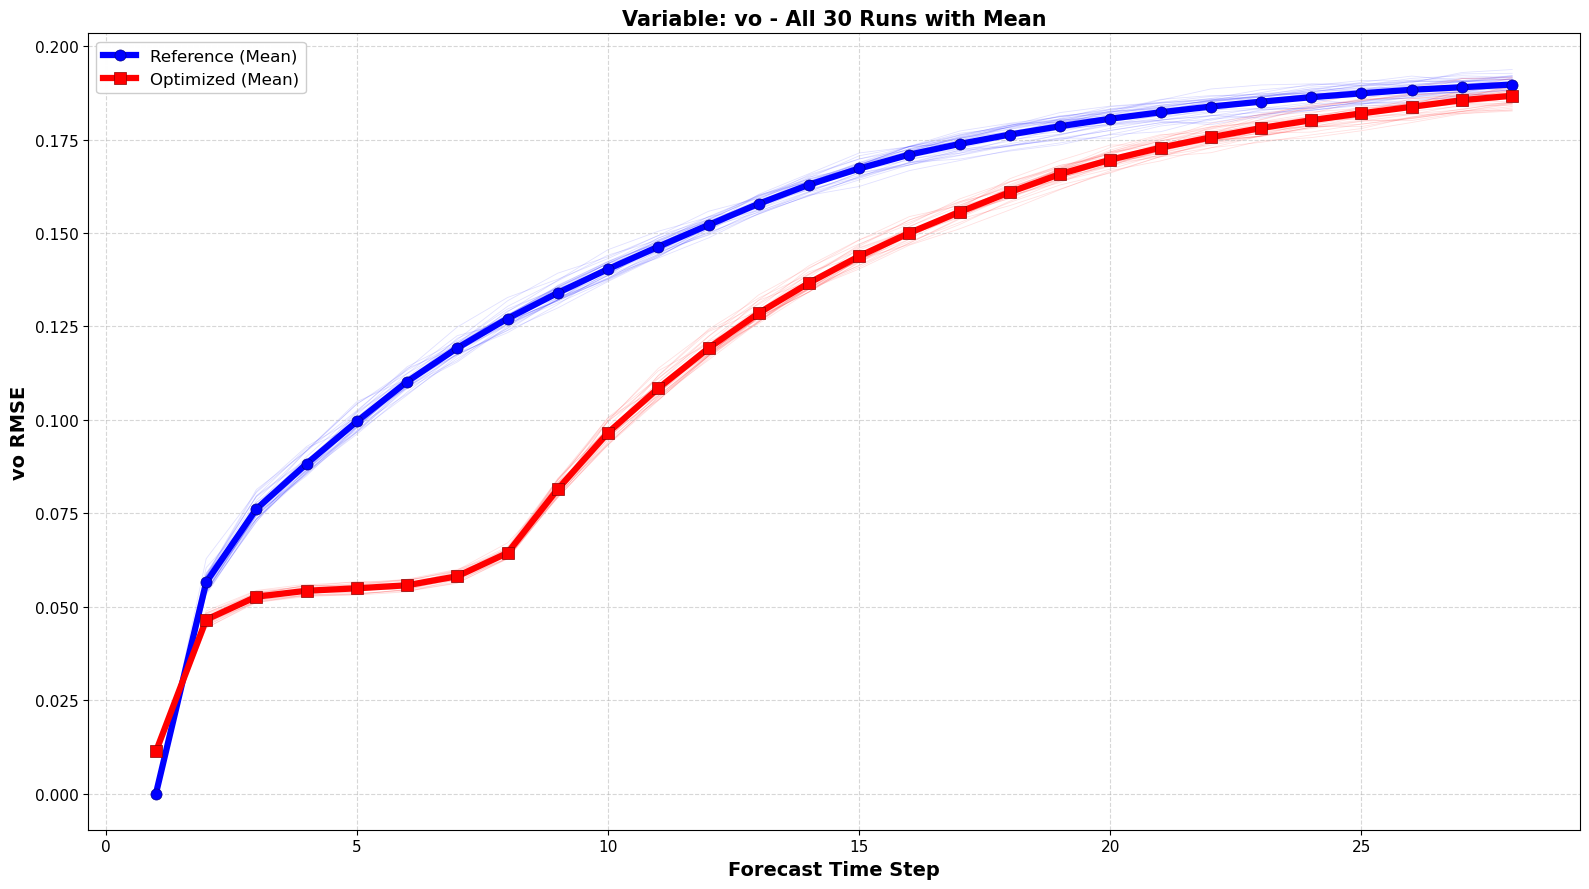

In [ ]:
# Create per-variable superposed plots (all 30 runs + mean for each channel)
# Get channel names from first run
channels = list(processed_data[0]['channels'])

# Determine common length across runs to avoid length mismatches
min_len = min(len(data['steps']) for data in processed_data.values())

for ch_idx, channel in enumerate(channels):
    fig, ax = plt.subplots(1, 1, figsize=(16, 9))
    
    # Collect all reference and optimized data for this channel across all runs
    all_ref_ch = []
    all_opt_ch = []
    steps = None
    
    for idx in sorted(processed_data.keys()):
        data = processed_data[idx]
        data_steps = data['steps'][:min_len]
        all_ref_ch.append(data['reference_rmse'][:min_len, ch_idx])
        all_opt_ch.append(data['optimized_rmse'][:min_len, ch_idx])
        if steps is None:
            steps = data_steps
    
    # Convert to arrays
    all_ref_ch = np.array(all_ref_ch)
    all_opt_ch = np.array(all_opt_ch)
    
    # Compute means
    ref_ch_mean = np.mean(all_ref_ch, axis=0)
    opt_ch_mean = np.mean(all_opt_ch, axis=0)
    
    # Plot individual runs as thin lines (ensemble members)
    # Reference (blue)
    for i, idx in enumerate(sorted(processed_data.keys())):
        data = processed_data[idx]
        data_steps = data['steps'][:min_len]
        ax.plot(data_steps, data['reference_rmse'][:min_len, ch_idx], color='blue', alpha=0.12, linewidth=0.6, zorder=1)
    
    # Optimized (red)
    for i, idx in enumerate(sorted(processed_data.keys())):
        data = processed_data[idx]
        data_steps = data['steps'][:min_len]
        ax.plot(data_steps, data['optimized_rmse'][:min_len, ch_idx], color='red', alpha=0.12, linewidth=0.6, zorder=1)
    
    # Plot bold mean lines on top with markers
    ax.plot(steps, ref_ch_mean, color='blue', linewidth=4.5, label='Reference (Mean)', marker='o', 
            markersize=8, markeredgewidth=0.5, markeredgecolor='darkblue', zorder=10)
    ax.plot(steps, opt_ch_mean, color='red', linewidth=4.5, label='Optimized (Mean)', marker='s', 
            markersize=8, markeredgewidth=0.5, markeredgecolor='darkred', zorder=10)
    
    ax.set_xlabel('Forecast Time Step', fontsize=14, fontweight='bold')
    ax.set_ylabel(f'{channel} RMSE', fontsize=14, fontweight='bold')
    ax.set_title(f'Variable: {channel} - All 30 Runs with Mean', fontsize=15, fontweight='bold')
    ax.legend(loc='best', fontsize=12, framealpha=0.98)
    ax.grid(True, alpha=0.5, linestyle='--')
    ax.tick_params(axis='both', which='major', labelsize=11)
    
    plt.tight_layout()
    plot_filename = f'superposed_rmse_{channel.lower()}.png'
    plt.savefig(os.path.join(database_path, plot_filename), dpi=150, bbox_inches='tight')
    print(f"Saved: {plot_filename}")
    plt.show()
